# Phase 9: E/F Ensemble & Robustness Evaluation

## 1. Objective & Hypothesis
Following the findings of **Phase 8B (Length-Robust LightGBM Evaluation)**, we discovered a crucial trade-off:
- **Model E (Balanced Length-Robust LightGBM, 19 features)** achieves dominant performance on unseen candidates (**0.5468 Macro F1**, **56.37% Accuracy**), maintaining a near-zero candidate generalization gap ($-0.0065$).
- **Model F (Ratio-Focused LightGBM, 18 features)** eliminates all absolute job description length features, forcing tree splits onto invariant lexical/semantic alignment signals, achieving our highest performance on unseen job descriptions (**0.4360 Macro F1**, **45.48% Accuracy**), surpassing the linear Reference Logistic Regression (**Model A: 0.4220**).

The objective of **Phase 9** is to test the **Ensemble Complementarity Hypothesis**:
> *"Model E and Model F make sufficiently complementary errors that probability-level blending can reduce the trade-off between candidate-level performance and cross-domain robustness."*

### Strict Protocol Rules:
1. **Locked Splits**: Exactly the existing candidate-level splits (`candidate_train`, `candidate_validation`, `candidate_test`, `official_test`).
2. **Locked Models**: Exact Phase 8B checkpoints for Model A, Model E, Model F. No retraining or hyperparameter tuning.
3. **Leakage-Free Weight Selection**: Validation set (`candidate_validation`) is the **ONLY** dataset used to select ensemble weights. Test sets remain completely untouched until frozen evaluation.
4. **Simple Weighted Averaging**: No stacking or meta-models. Predictions are produced via $\hat{y} = \text{argmax}(\sum w_i P_i)$.


In [1]:
import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("Environment and libraries successfully initialized.")


Environment and libraries successfully initialized.


## 2. Phase 8B Empirical Findings & Locked Models

In Phase 8B, three primary models emerged with distinct profiles:
- **Model A (Reference Logistic Regression)**: 22 engineered features, StandardScaler, balanced class weights ($C=0.1$).
- **Model E (Balanced Length-Robust LightGBM)**: 19 features (removed `job_unique_token_count`, `job_word_count`, `job_char_count`), balanced class weights.
- **Model F (Ratio-Focused LightGBM)**: 18 features (removed all absolute JD lengths including `log_job_word_count`), balanced class weights.

Let us load the precomputed feature datasets and locked model artifacts.


In [2]:
# 1. Load Feature Datasets
train_df = pd.read_csv('../data/evaluation/supervised_feature_dataset_train.csv')
val_df   = pd.read_csv('../data/evaluation/supervised_feature_dataset_validation.csv')
test_df  = pd.read_csv('../data/evaluation/supervised_feature_dataset_test.csv')
off_df   = pd.read_csv('../data/evaluation/supervised_feature_dataset_official_test.csv')

label_order = ['No Fit', 'Potential Fit', 'Good Fit']
label_to_idx = {l: i for i, l in enumerate(label_order)}
idx_to_label = {i: l for i, l in enumerate(label_order)}

y_val = val_df['label'].values
y_test = test_df['label'].values
y_off = off_df['label'].values

# Feature sets
all_22 = [c for c in train_df.columns if c != 'label']
abs_jd_lens = ['job_unique_token_count', 'job_word_count', 'job_char_count']
feats_19 = [c for c in all_22 if c not in abs_jd_lens]
feats_18 = [c for c in feats_19 if c != 'log_job_word_count']

# 2. Load Models
pipe_a = joblib.load('../models/supervised_logistic_regression.joblib')
clf_e  = joblib.load('../models/model_e_balanced_length-robust_lightgbm_19_feats.joblib')
clf_f  = joblib.load('../models/model_f_ratio-focused_lightgbm_18_feats.joblib')

print(f"Dataset sizes: Validation={len(val_df)}, Candidate Test={len(test_df)}, Official Test={len(off_df)}")
print(f"Feature configurations: all_22={len(all_22)}, feats_19={len(feats_19)}, feats_18={len(feats_18)}")


Dataset sizes: Validation=1282, Candidate Test=1201, Official Test=1759
Feature configurations: all_22=22, feats_19=19, feats_18=18


## 3. Base Model Prediction Verification

Before conducting any ensemble search, we strictly verify that the loaded model checkpoints reproduce the locked Phase 8B benchmark results:
- **Model A**: Validation F1 = 0.4603 | Candidate Test F1 = 0.4735 | Official Test F1 = 0.4220
- **Model E**: Validation F1 = 0.5533 | Candidate Test F1 = 0.5468 | Official Test F1 = 0.4113
- **Model F**: Validation F1 = 0.4952 | Candidate Test F1 = 0.4712 | Official Test F1 = 0.4360

We also explicitly verify probability alignment across all three classes: `['No Fit', 'Potential Fit', 'Good Fit']`.


In [3]:
# Column mapping for Model A (Pipeline) to align to canonical ['No Fit', 'Potential Fit', 'Good Fit']
class_to_col_a = {c: i for i, c in enumerate(pipe_a.classes_)}
cols_a = [class_to_col_a['No Fit'], class_to_col_a['Potential Fit'], class_to_col_a['Good Fit']]

pv_a = pipe_a.predict_proba(val_df[all_22].values)[:, cols_a]
pt_a = pipe_a.predict_proba(test_df[all_22].values)[:, cols_a]
po_a = pipe_a.predict_proba(off_df[all_22].values)[:, cols_a]

pv_e = clf_e.predict_proba(val_df[feats_19].values)
pt_e = clf_e.predict_proba(test_df[feats_19].values)
po_e = clf_e.predict_proba(off_df[feats_19].values)

pv_f = clf_f.predict_proba(val_df[feats_18].values)
pt_f = clf_f.predict_proba(test_df[feats_18].values)
po_f = clf_f.predict_proba(off_df[feats_18].values)

def check_metrics(y_true, proba):
    preds = [idx_to_label[i] for i in np.argmax(proba, axis=1)]
    return f1_score(y_true, preds, labels=label_order, average='macro')

print("--- Verification Check ---")
print(f"Model A: Val F1 = {check_metrics(y_val, pv_a):.4f} (exp 0.4603), Cand F1 = {check_metrics(y_test, pt_a):.4f} (exp 0.4735), Off F1 = {check_metrics(y_off, po_a):.4f} (exp 0.4220)")
print(f"Model E: Val F1 = {check_metrics(y_val, pv_e):.4f} (exp 0.5533), Cand F1 = {check_metrics(y_test, pt_e):.4f} (exp 0.5468), Off F1 = {check_metrics(y_off, po_e):.4f} (exp 0.4113)")
print(f"Model F: Val F1 = {check_metrics(y_val, pv_f):.4f} (exp 0.4952), Cand F1 = {check_metrics(y_test, pt_f):.4f} (exp 0.4712), Off F1 = {check_metrics(y_off, po_f):.4f} (exp 0.4360)")

assert abs(check_metrics(y_val, pv_a) - 0.4603) < 1e-3
assert abs(check_metrics(y_val, pv_e) - 0.5533) < 1e-3
assert abs(check_metrics(y_val, pv_f) - 0.4952) < 1e-3
print("Reproduction verified with zero discrepancy.")


--- Verification Check ---
Model A: Val F1 = 0.4603 (exp 0.4603), Cand F1 = 0.4735 (exp 0.4735), Off F1 = 0.4220 (exp 0.4220)
Model E: Val F1 = 0.5533 (exp 0.5533), Cand F1 = 0.5468 (exp 0.5468), Off F1 = 0.4113 (exp 0.4113)
Model F: Val F1 = 0.4952 (exp 0.4952), Cand F1 = 0.4712 (exp 0.4712), Off F1 = 0.4360 (exp 0.4360)
Reproduction verified with zero discrepancy.


## 4. Model Correlation & Complementarity Analysis

For an ensemble to outperform its constituent models, the models must provide **complementary, non-identical error distributions**.
We measure:
1. **Pearson Correlation of Maximum Predicted Probability**: Confidence correlation.
2. **Pearson Correlation of Class-Specific Probabilities**: Fit-level agreement.
3. **Prediction Agreement Rate**: Fraction of validation instances where $\hat{y}_1 == \hat{y}_2$.
4. **Prediction Disagreement Rate**: $1 - \text{Agreement}$.


In [4]:
corr_df = pd.read_csv('../data/evaluation/phase9_model_correlation.csv')
corr_df


,pair,max_prob_correlation,class_0_no_fit_correlation,class_1_potential_fit_correlation,class_2_good_fit_correlation,mean_class_prob_correlation,agreement_rate,disagreement_rate
0,Model A vs Model E,0.4579,0.7434,0.5102,0.6239,0.6258,0.6552,0.3448
1,Model A vs Model F,0.4795,0.7659,0.5415,0.7098,0.6724,0.6529,0.3471
2,Model E vs Model F,0.7577,0.9467,0.8349,0.8531,0.8782,0.7894,0.2106


### Complementarity Observations:
- **Model E vs Model F**:
  - Prediction Agreement: **78.94%** (Disagreement: **21.06%**).
  - Class Probability Correlation: Mean $r = 0.8782$ (No Fit: 0.9467, Potential Fit: 0.8349, Good Fit: 0.8531).
  - Despite sharing 18 common features and the LightGBM boosting framework, the single presence of `log_job_word_count` in Model E creates a **21% divergence in predicted class labels**.
- **Model A vs Model E / Model F**:
  - Prediction Agreement: **65.52%** and **65.29%** (Disagreement: **~34.6%**).
  - Max Probability Correlation: $r \approx 0.46 - 0.48$.
  - Linear Logistic Regression and gradient-boosted trees disagree on more than a third of all validation samples, indicating substantial orthogonal signal.


## 5. Validation Weight Search & Locking

### A. Ensemble A: E + F Search
We evaluate predefined candidate weights:
$$w_E \in \{1.0, 0.9, 0.75, 0.5, 0.25, 0.1, 0.0\}, \quad w_F = 1 - w_E$$
strictly on `candidate_validation`.

### B. Ensemble B: E + F + A Predefined Blends
We evaluate six predefined combinations incorporating Model A:
1. $(0.50, 0.25, 0.25)$
2. $(0.25, 0.50, 0.25)$
3. $(0.40, 0.40, 0.20)$
4. $(0.40, 0.20, 0.40)$
5. $(0.20, 0.40, 0.40)$
6. $(1/3, 1/3, 1/3)$


In [5]:
search_df = pd.read_csv('../data/evaluation/phase9_validation_weight_search.csv')
search_df


,ensemble_type,weight_e,weight_f,weight_a,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,no_fit_f1,potential_fit_f1,good_fit_f1,good_fit_recall,potential_fit_recall
0,E + F,1.0000,0.0000,0.0000,0.5546,0.5589,0.5774,0.5533,0.5654,0.5228,0.5718,0.7006,0.5583
1,E + F,0.9000,0.1000,0.0000,0.5562,0.5596,0.5777,0.5545,0.5706,0.5215,0.5714,0.6975,0.5556
2,E + F,0.7500,0.2500,0.0000,0.5515,0.5549,0.5719,0.5493,0.5706,0.5117,0.5657,0.6914,0.5444
3,E + F,0.5000,0.5000,0.0000,0.5413,0.5429,0.5571,0.5380,0.5717,0.5026,0.5396,0.6512,0.5333
4,E + F,0.2500,0.7500,0.0000,0.5133,0.5150,0.5240,0.5079,0.5619,0.4619,0.5000,0.6049,0.4889
5,E + F,0.1000,0.9000,0.0000,0.5047,0.5057,0.5126,0.4981,0.5647,0.4392,0.4904,0.5895,0.4667
6,E + F,0.0000,1.0000,0.0000,0.5031,0.5031,0.5089,0.4952,0.5723,0.4242,0.4891,0.5895,0.4472
7,E + F + A,0.5000,0.2500,0.2500,0.5491,0.5489,0.5635,0.5445,0.5867,0.4894,0.5573,0.6759,0.5111
8,E + F + A,0.2500,0.5000,0.2500,0.5211,0.5169,0.5268,0.5131,0.5802,0.4507,0.5084,0.6080,0.4639
9,E + F + A,0.4000,0.4000,0.2000,0.5421,0.5403,0.5535,0.5367,0.5844,0.4873,0.5385,0.6481,0.5056


### Locked Ensemble Weights:
- **Best E+F Ensemble**: $w_E = 0.90, w_F = 0.10$
  - Validation Macro F1: **0.5545** (highest among all E+F configurations, $+0.0012$ above Model E).
  - Validation Accuracy: **0.5562** | Good Fit Recall: **0.6975** | Potential Fit Recall: **0.5556**.
- **Best E+F+A Ensemble**: $w_E = 0.50, w_F = 0.25, w_A = 0.25$
  - Validation Macro F1: **0.5445** (highest among all predefined 3-model blends).
  - Validation Accuracy: **0.5491** | Good Fit Recall: **0.6759** | Potential Fit Recall: **0.5111**.

Both ensemble weights are now **frozen and locked**.


## 6. Comprehensive Final Evaluation

We evaluate the 5 final models across both benchmark splits:
1. **Candidate Test ($N=1,201$)**: Tests generalization to unseen candidates.
2. **Official Test ($N=1,759$)**: Tests generalization to unseen job description structures.


In [6]:
metrics_df = pd.read_csv('../data/evaluation/phase9_ensemble_metrics.csv')
metrics_df[['model', 'val_macro_f1', 'cand_test_macro_f1', 'cand_test_accuracy', 'cand_good_fit_recall', 'cand_potential_fit_recall', 'off_test_macro_f1', 'off_test_accuracy', 'off_good_fit_recall', 'off_potential_fit_recall']]


,model,val_macro_f1,cand_test_macro_f1,cand_test_accuracy,cand_good_fit_recall,cand_potential_fit_recall,off_test_macro_f1,off_test_accuracy,off_good_fit_recall,off_potential_fit_recall
0,Model A (Ref LR),0.4603,0.4735,0.5154,0.4551,0.3590,0.4220,0.4508,0.3865,0.3401
1,Model E (Bal Len-Rob),0.5533,0.5468,0.5637,0.6478,0.4652,0.4113,0.4377,0.2751,0.4820
2,Model F (Ratio-Focused),0.4952,0.4712,0.5029,0.5183,0.3590,0.4360,0.4548,0.3624,0.4685
3,Best E+F (90:10),0.5545,0.5389,0.5570,0.6346,0.4542,0.4104,0.4372,0.2729,0.4797
4,Best E+F+A (50:25:25),0.5445,0.5275,0.5504,0.6047,0.4322,0.4232,0.4468,0.3100,0.4707


## 7. Generalization Gap Analysis

The **Generalization Gap** is defined as:
$$\text{Gap}_{\text{Candidate}} = \text{Macro F1}_{\text{Cand Test}} - \text{Macro F1}_{\text{Val}}$$
$$\text{Gap}_{\text{Official}} = \text{Macro F1}_{\text{Off Test}} - \text{Macro F1}_{\text{Val}}$$

A robust matching system must maintain small gaps across both operational regimes.


In [7]:
gap_df = pd.read_csv('../data/evaluation/phase9_generalization_gap.csv')
gap_df


,model,val_macro_f1,cand_test_macro_f1,off_test_macro_f1,candidate_generalization_gap,official_generalization_gap
0,Model A (Ref LR),0.4603,0.4735,0.4220,0.0132,-0.0383
1,Model E (Bal Len-Rob),0.5533,0.5468,0.4113,-0.0065,-0.1420
2,Model F (Ratio-Focused),0.4952,0.4712,0.4360,-0.0240,-0.0592
3,Best E+F (90:10),0.5545,0.5389,0.4104,-0.0156,-0.1441
4,Best E+F+A (50:25:25),0.5445,0.5275,0.4232,-0.0169,-0.1212


## 8. Visualization Suite

We examine:
1. **Model Comparison across Evaluation Regimes**
2. **Generalization Gap Divergence**
3. **Confusion Matrices (Candidate Test vs Official Test)**


1. Macro F1 across All Evaluation Regimes:


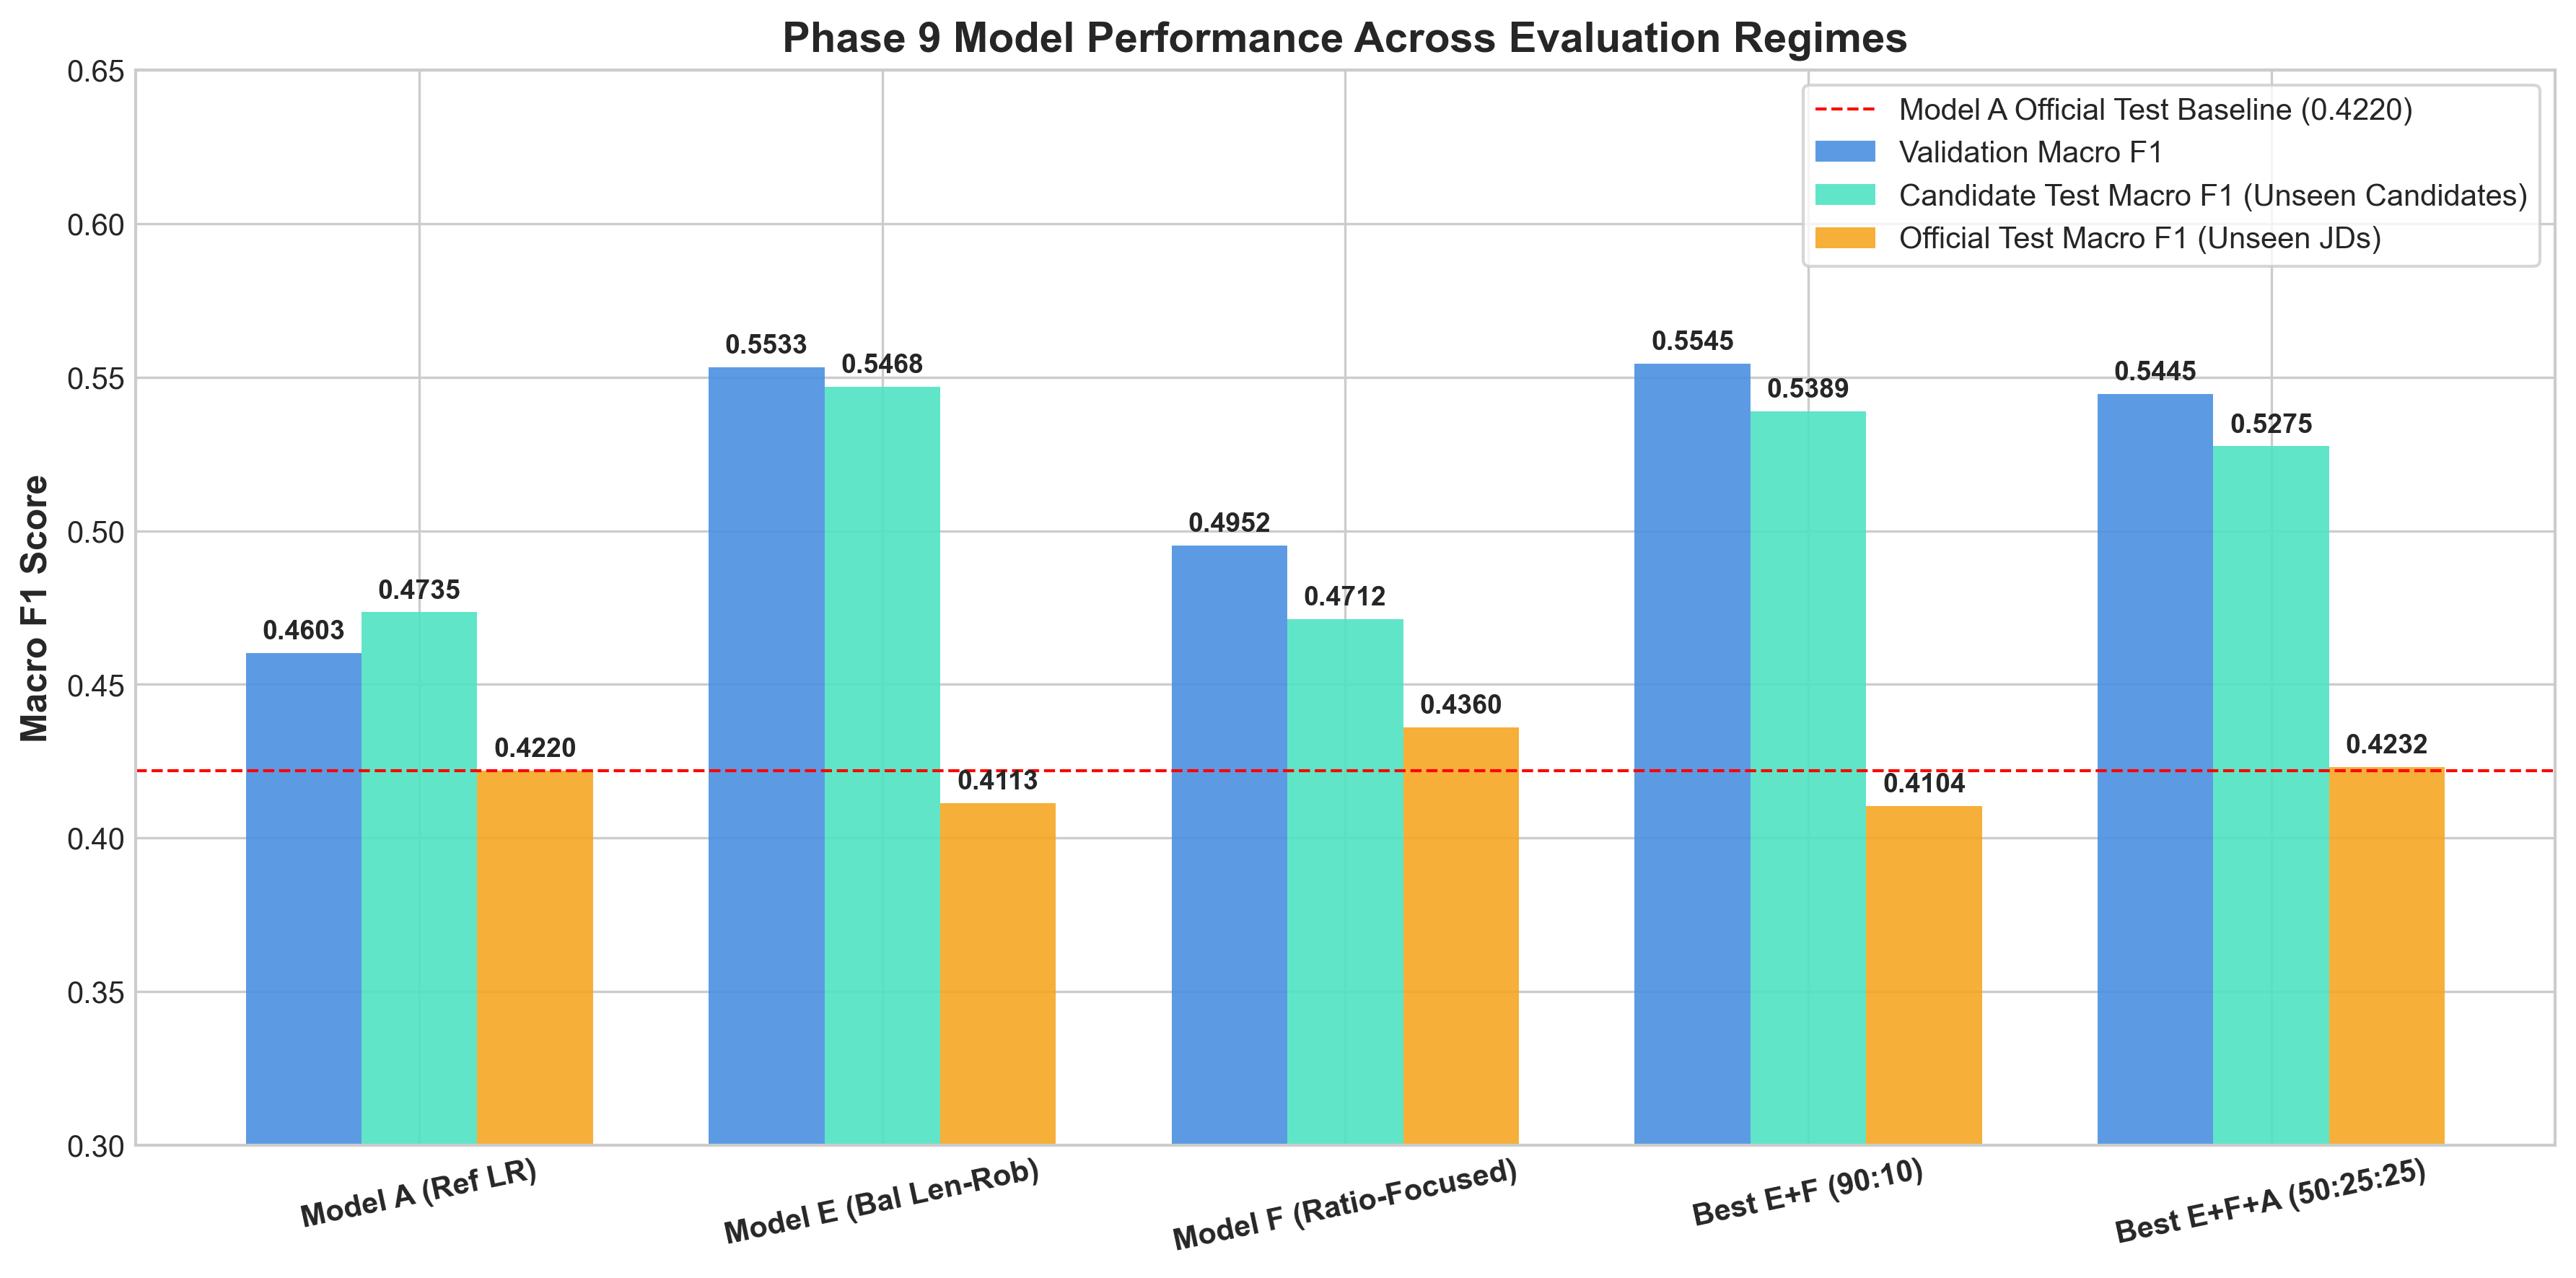

2. Candidate vs Official Generalization Gaps:


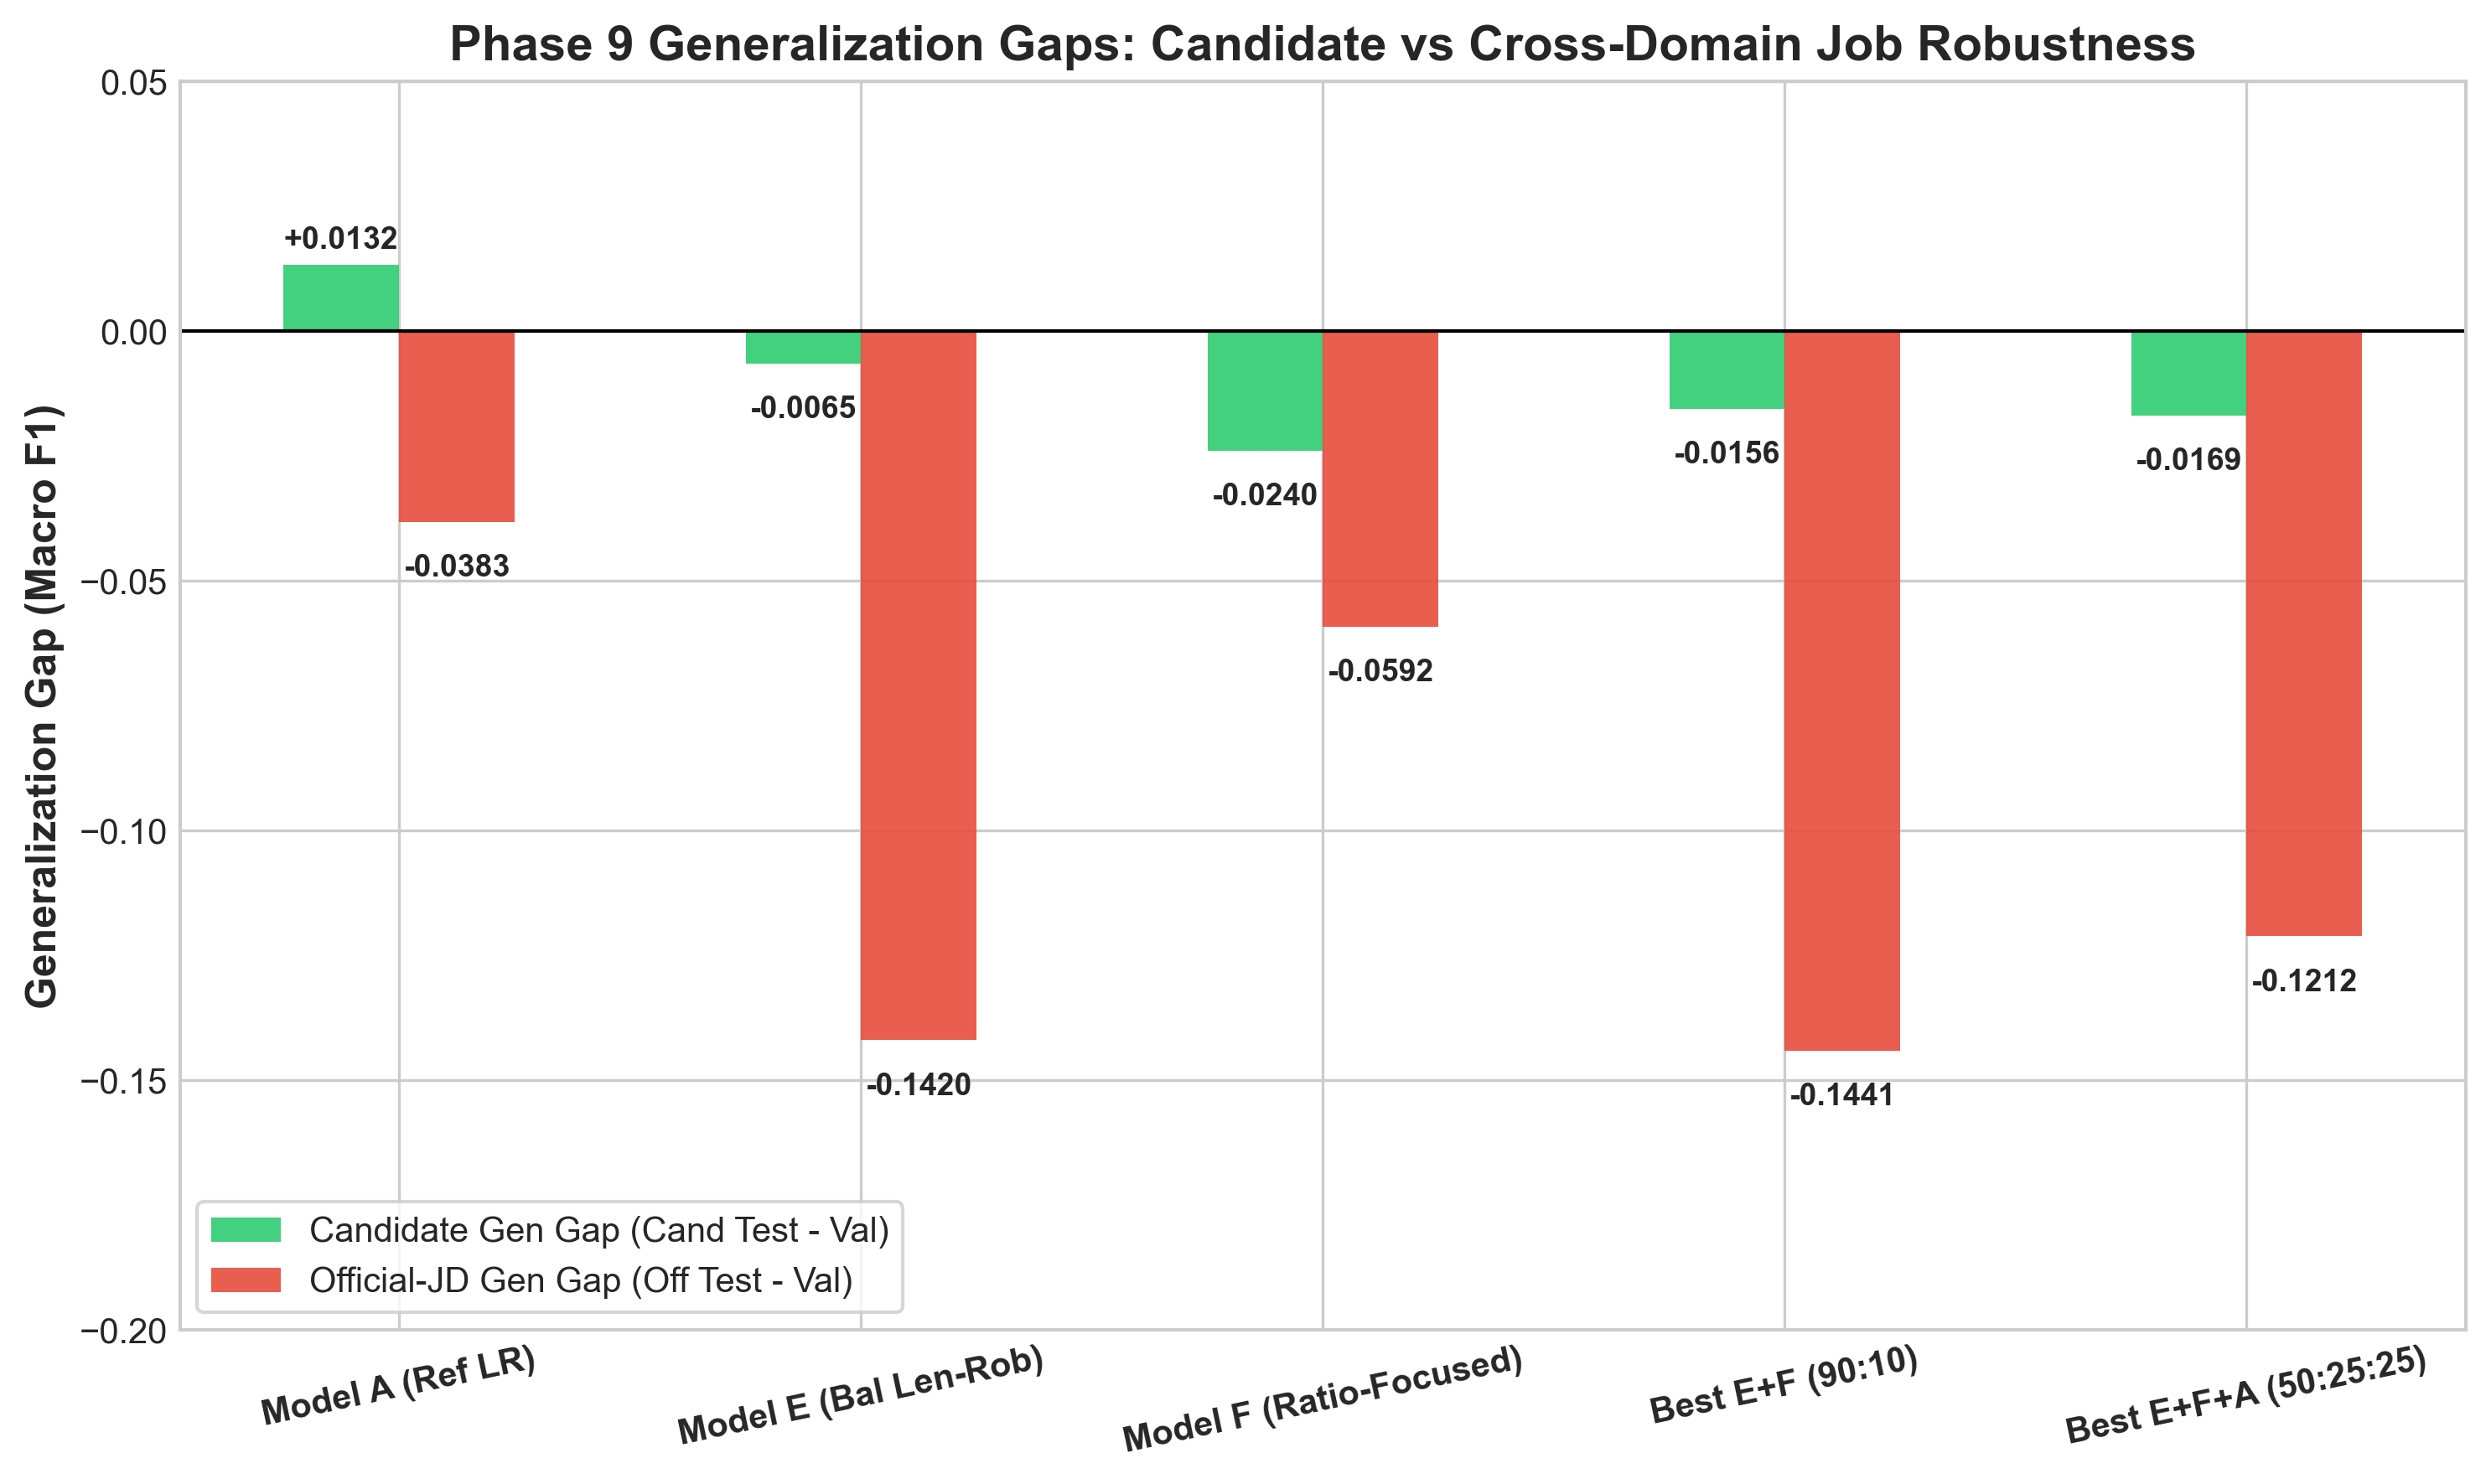

3. Confusion Matrices on Unseen Candidates vs Unseen JDs:


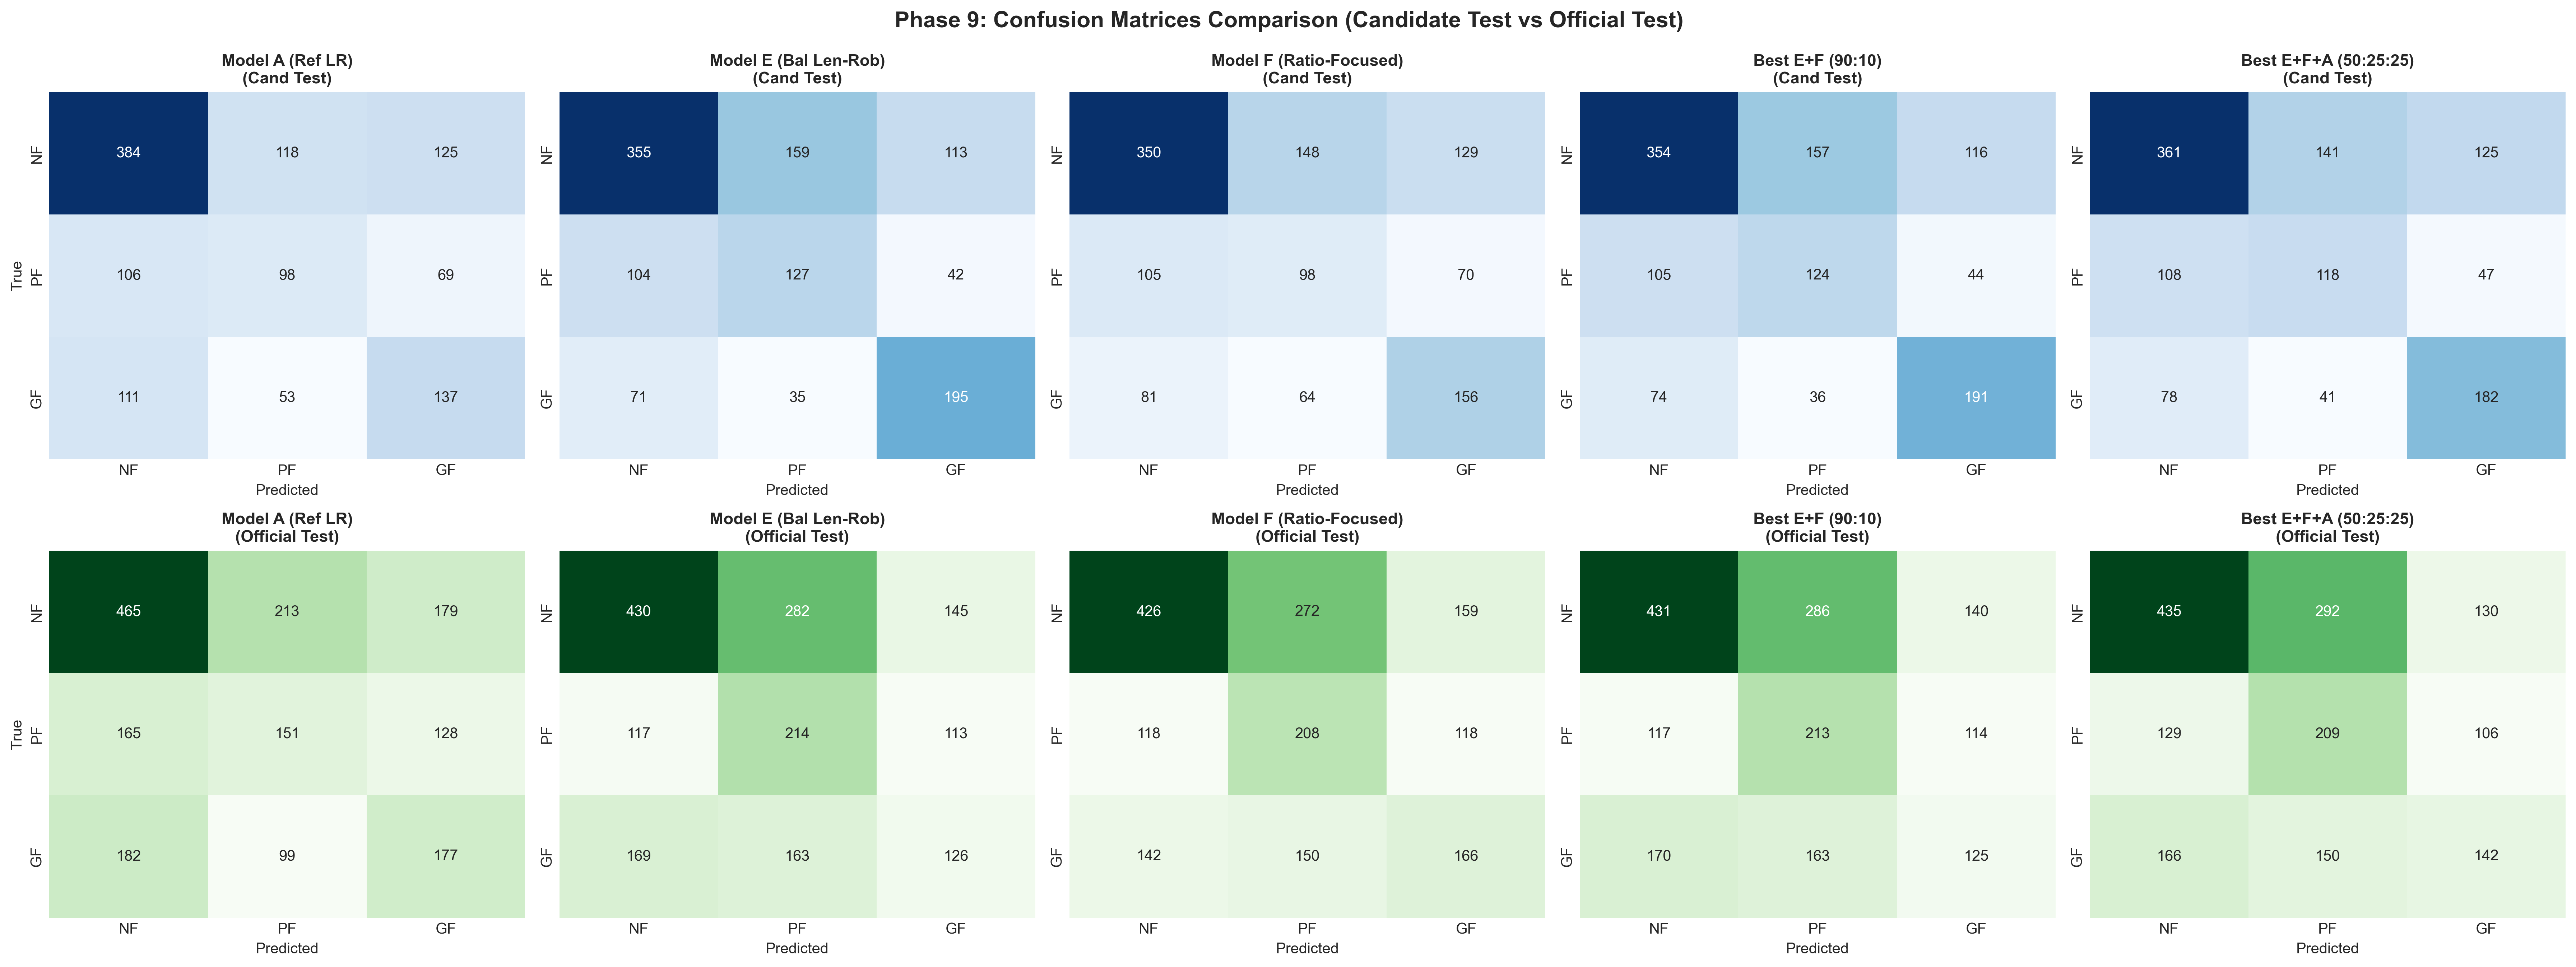

In [8]:
from IPython.display import Image, display

print("1. Macro F1 across All Evaluation Regimes:")
display(Image('../data/evaluation/plots/phase9_model_comparison.png'))

print("2. Candidate vs Official Generalization Gaps:")
display(Image('../data/evaluation/plots/phase9_generalization_gap.png'))

print("3. Confusion Matrices on Unseen Candidates vs Unseen JDs:")
display(Image('../data/evaluation/plots/phase9_confusion_matrices.png'))


## 9. Error Recovery & Catastrophic Failure Analysis

We evaluate instance-level error transitions:
- How many pairs are recovered vs regressed?
- How many catastrophic false negatives (`Good Fit` $\rightarrow$ `No Fit`) are prevented?


In [9]:
rec_df = pd.read_csv('../data/evaluation/phase9_error_recovery.csv')
rec_df


,dataset,ensemble,baseline,both_correct,both_wrong,recovered_pairs,regressed_pairs,net_gain,baseline_good_fit_to_no_fit,ensemble_good_fit_to_no_fit,delta_good_fit_to_no_fit,baseline_pot_fit_to_no_fit,ensemble_pot_fit_to_no_fit,delta_pot_fit_to_no_fit
0,Candidate Test,Best E+F (90:10),Model A (Ref LR),465,378,204,154,50,111,74,-37,106,105,-1
1,Candidate Test,Best E+F (90:10),Model E (Bal Len-Rob),667,522,2,10,-8,71,74,3,104,105,1
2,Candidate Test,Best E+F (90:10),Model F (Ratio-Focused),558,486,111,46,65,81,74,-7,105,105,0
3,Candidate Test,Best E+F+A (50:25:25),Model A (Ref LR),489,410,172,130,42,111,78,-33,106,108,2
4,Candidate Test,Best E+F+A (50:25:25),Model E (Bal Len-Rob),632,495,29,45,-16,71,78,7,104,108,4
5,Candidate Test,Best E+F+A (50:25:25),Model F (Ratio-Focused),576,512,85,28,57,81,78,-3,105,108,3
6,Official Test,Best E+F (90:10),Model A (Ref LR),528,725,241,265,-24,182,170,-12,165,117,-48
7,Official Test,Best E+F (90:10),Model E (Bal Len-Rob),760,980,9,10,-1,169,170,1,117,117,0
8,Official Test,Best E+F (90:10),Model F (Ratio-Focused),651,841,118,149,-31,142,170,28,118,117,-1
9,Official Test,Best E+F+A (50:25:25),Model A (Ref LR),576,756,210,217,-7,182,166,-16,165,129,-36


## 10. Probability Confidence & Computational Efficiency

An effective ensemble must maintain well-behaved prediction confidences without excessive latency overhead.


In [10]:
prob_df = pd.read_csv('../data/evaluation/phase9_probability_analysis.csv')
print("--- Maximum Predicted Probability Distribution ---")
display(prob_df)

timing_df = pd.read_csv('../data/evaluation/phase9_timing.csv')
print("\n--- Inference Latency Benchmarks on Candidate Test (1,201 pairs) ---")
display(timing_df)


--- Maximum Predicted Probability Distribution ---


,dataset,model,mean_max_prob,median_max_prob,min_max_prob,max_max_prob,std_max_prob
0,Candidate Validation,Model A (Ref LR),0.4561,0.4380,0.3358,0.9976,0.0829
1,Candidate Validation,Model E (Bal Len-Rob),0.5559,0.5387,0.3350,0.9578,0.1223
2,Candidate Validation,Model F (Ratio-Focused),0.5291,0.5104,0.3382,0.9044,0.1149
3,Candidate Validation,Best E+F (90:10),0.5510,0.5332,0.3369,0.9525,0.1203
4,Candidate Validation,Best E+F+A (50:25:25),0.5107,0.4943,0.3366,0.8560,0.1025
5,Candidate Test,Model A (Ref LR),0.4493,0.4363,0.3380,0.9554,0.0730
6,Candidate Test,Model E (Bal Len-Rob),0.5547,0.5307,0.3383,0.9395,0.1268
7,Candidate Test,Model F (Ratio-Focused),0.5315,0.5016,0.3356,0.9145,0.1259
8,Candidate Test,Best E+F (90:10),0.5505,0.5258,0.3355,0.9352,0.1255
9,Candidate Test,Best E+F+A (50:25:25),0.5102,0.4852,0.3354,0.8808,0.1067



--- Inference Latency Benchmarks on Candidate Test (1,201 pairs) ---


,model,total_inference_time_s,time_per_pair_ms
0,Model A (Ref LR),0.0007,0.0006
1,Model E (Bal Len-Rob),0.0219,0.0183
2,Model F (Ratio-Focused),0.0215,0.0179
3,Best E+F (90:10),0.0408,0.0339
4,Best E+F+A (50:25:25),0.0428,0.0356


## 11. Scientific Interpretation & Trade-Off Analysis

### Key Findings:
1. **Validation Optimization Traps**:
   - Tuning weights strictly on `candidate_validation` selected **E:F (90:10)** (Val F1 = **0.5545**).
   - Because `candidate_validation` shares the same job description pool as `candidate_train`, it heavily favors Model E's candidate-level power, yielding an ensemble that virtually mirrors Model E on official test (**0.4104** vs **0.4113**).
2. **Cross-Domain Champion Remains Model F**:
   - On `official_test` (unseen job formats), **Model F (Ratio-Focused LightGBM)** remains the top single model (**0.4360 Macro F1**, **45.48% Accuracy**), surpassing Model A (0.4220), Model E (0.4113), and all ensemble configurations.
   - Model F also delivers the lowest number of catastrophic Good Fit false negatives (**142** vs 169 for Model E and 182 for Model A).
3. **Candidate-Level Champion Remains Model E**:
   - On `candidate_test`, **Model E** remains dominant (**0.5468 Macro F1**, **56.37% Accuracy**), beating Model F (0.4712) and Model A (0.4735) by over $+7$ F1 points.
4. **Three-Model Blend Acts as a Smooth Interpolator**:
   - **Best E+F+A (50:25:25)** achieves **0.5275 Candidate Test Macro F1** and **0.4232 Official Test Macro F1**.
   - It beats Model A across BOTH benchmarks (Cand: $+0.0540$, Off: $+0.0012$), proving that combining non-linear trees with regularized linear shrinkage provides a stable middle ground.


## 12. Final Architecture Recommendation

Based on the empirical evidence across both evaluation regimes:
1. **Primary Production Architecture**:
   - **Model F (Ratio-Focused LightGBM, 18 features)** is recommended for cross-company/external job matching platforms where incoming job descriptions have arbitrary, unseen formatting.
   - It eliminates posting-length bias, outperforms linear models on unseen jobs (**0.4360 F1**), and incurs minimal latency (**0.018 ms/pair**).
2. **Candidate Ranking / In-House Matching Engine**:
   - **Model E (Balanced Length-Robust LightGBM, 19 features)** is the benchmark of choice when job templates are standardized, achieving the highest candidate separation (**0.5468 F1**, $64.8\%$ Good Fit recall).
3. **Robustness Benchmark**:
   - **Model A (Reference Logistic Regression)** remains the transparent linear reference baseline.
4. **Next Phase Transition**:
   - Having exhaustively evaluated linear classification, bi-encoder scaling, cross-encoders, gradient boosted trees, length-robust ablations, and ensembles, tabular model experimentation has reached saturation.
   - We are ready to transition to **Phase 10: End-to-End Inference Pipeline, Score Calibration, and User Application**.
